# Grouped-query attention: sharing keys and values between query heads

*Ainslie et al., "GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints", 2023 ([arXiv 2305.13245](https://arxiv.org/abs/2305.13245)). Notebook 1 of 9 in the "How LLMs build on each other" series.*

**TL;DR.** When a language model writes text one token at a time, it has to re-read the keys and values of every earlier token at every step. Those stored keys and values are the **KV cache**, and reading them from memory, not doing arithmetic, is what limits speed. In ordinary multi-head attention (MHA) each of the $H$ query heads has its own key head and its own value head. **Grouped-query attention (GQA) lets several query heads share one key/value head.** With $H$ query heads and $G$ key/value heads, the cache is $H/G$ times smaller. $G=H$ is plain MHA, $G=1$ is multi-query attention (MQA), and everything in between is GQA. Llama-style models, DeepSeek LLM 67B (64 query heads, 8 key/value heads) and Qwen3-8B (32 query heads, 8 key/value heads) all use it.

In this notebook we build it from scratch, prove it is just MHA with some heads tied together, measure the cache saving, reproduce the paper's recipe for converting an already trained MHA model into a GQA model, and measure what the saving costs in quality on a small language model.

| step | what we do |
|---|---|
| 1 | why decoding is limited by the KV cache, with numbers |
| 2 | attention with $H$ query heads and $G$ key/value heads, by hand |
| 3 | check: GQA is MHA with tied heads |
| 4 | the cache for real configurations |
| 5 | converting a trained MHA model: mean-pooling versus the alternatives |
| 6 | training with different $G$ from scratch |
| 7 | measuring a decode step on this machine |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import archkit as A                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. The KV cache is what decoding has to carry

A transformer generates one token per forward pass. To produce token $t$, each attention layer needs the keys and values of tokens $1\dots t$. Recomputing them every step would be wasteful, so they are computed once and stored. That store is the KV cache.

For one layer and one token, MHA stores one key vector and one value vector **per head**, each of width $d_h$:

$$ \text{cache per token per layer} = 2\,H\,d_h \quad\text{numbers.} $$

Now think about what one decoding step does. It reads the whole cache ($t$ tokens times that many numbers) and does only a few multiply-adds with each number it reads: one for the query-key score, one for the weighted value. A modern GPU can do hundreds of arithmetic operations in the time it takes to fetch one number from memory, so the arithmetic units wait. The step is **memory-bandwidth bound**, and the time is roughly proportional to the bytes of cache read. Make the cache smaller and every decoding step gets faster; it also lets more users' conversations fit in memory at once.

Here is the size for a mid-sized configuration. We pick 32 layers, 32 heads of width 128 (the shape of a 7B-class model), 16-bit numbers and an 8,192-token conversation:

In [2]:
L, H, dh, T, bytes_per = 32, 32, 128, 8192, 2
per_tok_layer = 2 * H * dh
total = per_tok_layer * L * T * bytes_per
print(f"numbers per token per layer (MHA): {per_tok_layer:,}")
print(f"cache for one 8192-token conversation: {total / 2**30:.2f} GiB")
print(f"a GPU with 80 GB left for cache holds about {int(80e9 // total)} such conversations at once")
check("MHA cache is 2*H*dh per token per layer", per_tok_layer == 8192)

numbers per token per layer (MHA): 8,192
cache for one 8192-token conversation: 4.00 GiB
a GPU with 80 GB left for cache holds about 18 such conversations at once
PASS - MHA cache is 2*H*dh per token per layer 


Eighteen conversations per 80 GB of cache space. That is the pressure GQA relieves: with 8 key/value heads instead of 32, the same space holds four times as many.

## 2. The mechanism, by hand

Multi-head attention projects the input $x\in\mathbb{R}^{d}$ into $H$ queries, $H$ keys and $H$ values, one triple per head. Head $h$ attends using only its own triple. The first idea in the 2019 paper that introduced **multi-query attention** (MQA, Shazeer) was: keep $H$ different queries, but use **one** key and **one** value for all of them. Different queries asking different questions of the same keys is still useful, and the cache shrinks by a factor of $H$.

GQA, the paper's contribution, is the dial between the two. Split the $H$ query heads into $G$ **groups** of $H/G$ heads. Each group has one key head and one value head, shared by all query heads in the group.

![The paper's Figure 2. Multi-head attention has H query, key and value heads. Multi-query has one key/value head. Grouped-query shares each key/value head between a group of query heads.](../../assets/architecture_gallery/gqa_fig2_grouped.png)

Reading the picture: in the left panel every query head (top row) has its own key and value head. In the right panel all query heads point at one. In the middle, heads are split into groups. Nothing else changes: the same softmax, the same output projection.

To make that concrete, here are 8 query heads and the key/value head each one reads, for three values of $G$:

In [3]:
H = 8
for G in [8, 4, 2, 1]:
    kv_of_q = [h // (H // G) for h in range(H)]          # query head h reads key/value head h // (H/G)
    name = "MHA" if G == H else "MQA" if G == 1 else f"GQA-{G}"
    print(f"{name:6s} G={G}  query head -> kv head: {kv_of_q}   cache = {G}/{H} of MHA")

MHA    G=8  query head -> kv head: [0, 1, 2, 3, 4, 5, 6, 7]   cache = 8/8 of MHA
GQA-4  G=4  query head -> kv head: [0, 0, 1, 1, 2, 2, 3, 3]   cache = 4/8 of MHA
GQA-2  G=2  query head -> kv head: [0, 0, 0, 0, 1, 1, 1, 1]   cache = 2/8 of MHA
MQA    G=1  query head -> kv head: [0, 0, 0, 0, 0, 0, 0, 0]   cache = 1/8 of MHA


Now the computation. We need only one operation we have not seen in plain attention: expanding $G$ key heads to $H$ so the shapes line up, by repeating each key head $H/G$ times in a row (`repeat_interleave`). Everything after that is ordinary attention.

Here is the whole layer in the kit. The only difference from MHA is that `wk` and `wv` produce `n_kv * dh` columns instead of `H * dh`, and one `repeat_interleave` line:

In [4]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(d))
        self.eps = eps

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w


def rope_angles(pos, dh, base=10000.0):
    """pos: integer tensor of any shape -> angles [..., dh/2]."""
    inv = base ** (-torch.arange(0, dh, 2, dtype=torch.float32) / dh)
    return pos.to(torch.float32)[..., None] * inv


def apply_rope(x, pos):
    """x: [..., dh] (pairs are (even, odd) channels); pos broadcasts against x[..., 0]."""
    ang = rope_angles(pos, x.shape[-1])
    c, s = ang.cos(), ang.sin()
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.empty_like(x)
    out[..., 0::2] = x1 * c - x2 * s
    out[..., 1::2] = x1 * s + x2 * c
    return out


def attend(q, k, v, mask, sink=None):
    """Explicit softmax attention.
    q [B,H,T,d]  k,v [B,H,S,d]  mask bool, broadcastable to [B,H,T,S] (True = may look)
    sink: optional [H] learned logit. It is one extra softmax column that has no value vector:
          the probability it takes is simply thrown away (gpt-oss style).
    returns out [B,H,T,d], probs [B,H,T,S] (without the sink column)."""
    B, H, T, d = q.shape
    s = (q @ k.transpose(-1, -2)) / math.sqrt(d)
    s = s.masked_fill(~mask, float("-inf"))
    if sink is not None:
        s = torch.cat([s, sink.view(1, H, 1, 1).expand(B, H, T, 1)], dim=-1)
    p = s.softmax(-1)
    if sink is not None:
        p = p[..., :-1]
    return p @ v, p

class Attn(nn.Module):
    """Causal self-attention with the knobs this series studies.

    n_kv      number of key/value heads (n_kv == n_heads is MHA, 1 is MQA, in between is GQA)
    gate      None | "head" | "elem": sigmoid gate on the attention output, computed from the layer input
    sink      True: one learned sink logit per head
    """
    def __init__(self, d, n_heads, n_kv=None, gate=None, sink=False, rope=True):
        super().__init__()
        n_kv = n_kv or n_heads
        assert n_heads % n_kv == 0
        self.d, self.H, self.Hkv, self.dh = d, n_heads, n_kv, d // n_heads
        self.wq = nn.Linear(d, n_heads * self.dh, bias=False)
        self.wk = nn.Linear(d, n_kv * self.dh, bias=False)
        self.wv = nn.Linear(d, n_kv * self.dh, bias=False)
        self.wo = nn.Linear(n_heads * self.dh, d, bias=False)
        self.gate = gate
        if gate == "elem":
            self.wg = nn.Linear(d, n_heads * self.dh, bias=False)
        elif gate == "head":
            self.wg = nn.Linear(d, n_heads, bias=False)
        self.sink = nn.Parameter(torch.zeros(n_heads)) if sink else None
        self.rope = rope
        self.keep = False                    # set True to store the attention probabilities in self.p
        self.p = None
        self.g = None

    def split(self, x, n):
        B, T, _ = x.shape
        return x.view(B, T, n, self.dh).transpose(1, 2)

    def forward(self, x, window=None, n_sink_tokens=0, cache_pos=False, extra_mask=None):
        """window: keep only the last `window` tokens (sliding-window attention).
        n_sink_tokens: in addition keep the first n tokens forever (StreamingLLM).
        cache_pos: give RoPE the position *inside the cache* rather than the original position.
        extra_mask: bool [B,T,T] (e.g. from DSA's top-k) ANDed onto the causal mask."""
        B, T, _ = x.shape
        q, k, v = self.split(self.wq(x), self.H), self.split(self.wk(x), self.Hkv), self.split(self.wv(x), self.Hkv)
        g = self.H // self.Hkv
        pos = torch.arange(T)
        if window is not None and cache_pos:
            out, p = self._streaming(q, k, v, window, n_sink_tokens)
        else:
            if self.rope:
                q, k = apply_rope(q, pos[None, None, :]), apply_rope(k, pos[None, None, :])
            k, v = k.repeat_interleave(g, 1), v.repeat_interleave(g, 1)
            i, j = pos[:, None], pos[None, :]
            mask = j <= i
            if window is not None:
                mask = mask & ((i - j < window) | (j < n_sink_tokens))
            mask = mask[None, None]
            if extra_mask is not None:
                mask = mask & extra_mask[:, None]
            out, p = attend(q, k, v, mask, self.sink)
        if self.keep:
            self.p = p.detach()
        out = out.transpose(1, 2)                                   # [B,T,H,dh]
        if self.gate is not None:
            gs = torch.sigmoid(self.wg(x))
            self.g = gs.detach() if self.keep else None
            out = out * (gs.view(B, T, self.H, 1) if self.gate == "head" else gs.view(B, T, self.H, self.dh))
        return self.wo(out.reshape(B, T, self.H * self.dh))

    def _streaming(self, q, k, v, window, n_sink):
        """StreamingLLM: query t sees n_sink first tokens + the last `window` tokens, and RoPE uses the
        slot index inside that cache, so the model never sees a distance larger than n_sink+window."""
        B, H, T, dh = q.shape
        S = n_sink + window
        t = torch.arange(T)[:, None]                               # [T,1]
        slot = torch.arange(S)[None, :]                            # [1,S]
        n_cached = torch.clamp(t + 1, max=S)                       # entries in the cache when t is decoded
        # before eviction starts the cache holds tokens 0..t; afterwards sinks + the last `window` tokens
        evicting = (t + 1) > S
        tok = torch.where(evicting & (slot >= n_sink), t - (S - 1 - slot), slot)      # token index held in each slot
        valid = slot < n_cached
        tok = tok.clamp(0, T - 1)
        kg = k[:, :, tok]                                          # [B,Hkv,T,S,dh]
        vg = v[:, :, tok]
        g = H // self.Hkv
        kg, vg = kg.repeat_interleave(g, 1), vg.repeat_interleave(g, 1)
        qpos = (n_cached - 1)[None, None, :, 0]                    # [1,1,T]
        if self.rope:
            q = apply_rope(q, qpos)
            kg = apply_rope(kg, slot[None, None, :, :].expand(1, 1, T, S))
        s = (q[:, :, :, None, :] * kg).sum(-1) / math.sqrt(dh)     # [B,H,T,S]
        s = s.masked_fill(~valid[None, None], float("-inf"))
        if self.sink is not None:
            s = torch.cat([s, self.sink.view(1, H, 1, 1).expand(B, H, T, 1)], -1)
        p = s.softmax(-1)
        if self.sink is not None:
            p = p[..., :-1]
        out = (p[..., None] * vg).sum(3)
        return out, p

Read `forward` top to bottom. `q` has `H` heads, `k` and `v` have `Hkv` heads. `repeat_interleave(g, 1)` copies each key/value head `g = H/Hkv` times along the head axis, so head $h$ of `q` lines up with copy $h$. After that, `attend` is plain scaled dot-product attention with a causal mask. (The other options in this class, `gate`, `sink` and `window`, are used in later notebooks; here they stay off.)

## 3. Check: GQA is MHA with tied heads

If the reasoning above is right, a GQA layer with $G$ groups must give exactly the same output as an MHA layer whose key heads are copied from the GQA layer, each repeated $H/G$ times. No new capability, a constraint. We check by building both:

In [5]:
d, H, G = 32, 8, 2
dh = d // H
gqa, mha = A.Attn(d, H, n_kv=G), A.Attn(d, H, n_kv=H)
with torch.no_grad():
    mha.wq.weight.copy_(gqa.wq.weight); mha.wo.weight.copy_(gqa.wo.weight)
    for name in ["wk", "wv"]:
        w = getattr(gqa, name).weight.view(G, dh, d)                    # [G, dh, d]
        getattr(mha, name).weight.copy_(w.repeat_interleave(H // G, 0).reshape(H * dh, d))
x = torch.randn(3, 24, d)
err = (gqa(x) - mha(x)).abs().max().item()
print("max |GQA - MHA with tied heads| =", err)
check("GQA output equals MHA with its key/value heads copied across the group", err < 1e-6)

n_gqa = sum(p.numel() for p in gqa.parameters()); n_mha = sum(p.numel() for p in mha.parameters())
print(f"parameters: MHA {n_mha}  GQA-{G} {n_gqa}  ({n_gqa / n_mha:.2f}x)")
check("GQA has fewer parameters (smaller wk, wv)", n_gqa < n_mha)

max |GQA - MHA with tied heads| = 1.1920928955078125e-07
PASS - GQA output equals MHA with its key/value heads copied across the group 
parameters: MHA 4096  GQA-2 2560  (0.62x)
PASS - GQA has fewer parameters (smaller wk, wv) 


Two consequences to keep in mind. First, GQA is strictly **less expressive** than MHA at the same $H$: its key/value heads can only represent a subset of what MHA's can. Whether that matters in practice is an empirical question; we measure it in sections 5 and 6. Second, it also removes parameters (the smaller `wk` and `wv`), but in a large model these are a small part of the total, so the cache is the real saving.

## 4. The cache for real configurations

The cache per token per layer is $2\,G\,d_h$, so it scales with $G$ alone. Here are the configurations named in the diagram this series is based on, plus two others, expressed as the number of numbers cached per token per layer:

In [6]:
cfgs = [  # name, query heads, kv heads, head dim
    ("MHA (H=32, dh=128)", 32, 32, 128),
    ("Llama-2-70B-style GQA", 64, 8, 128),
    ("DeepSeek LLM 67B", 64, 8, 128),
    ("Qwen3-8B", 32, 8, 128),
    ("MQA (H=32)", 32, 1, 128),
]
print(f"{'config':26s} {'H':>3s} {'G':>3s} {'numbers/token/layer':>20s} {'vs MHA at same H':>18s}")
rows = []
for name, h, g, dhh in cfgs:
    c = 2 * g * dhh
    print(f"{name:26s} {h:3d} {g:3d} {c:20,d} {h / g:17.0f}x")
    rows.append((name, c))
check("Qwen3-8B-style 32/8 heads shrinks the cache 4x", 32 // 8 == 4)
# MLA from notebook 1 of the DeepSeek-V3 series: 512-dim latent + 64-dim rope key = 576 numbers
print(f"\nDeepSeek-V3's MLA caches 576 numbers per token per layer, the same as GQA with {576 / (2 * 128):.2f} groups of width 128.")
check("MLA's 576 numbers equal 2.25 GQA groups of 128", abs(576 / 256 - 2.25) < 1e-9)

config                       H   G  numbers/token/layer   vs MHA at same H
MHA (H=32, dh=128)          32  32                8,192                 1x
Llama-2-70B-style GQA       64   8                2,048                 8x
DeepSeek LLM 67B            64   8                2,048                 8x
Qwen3-8B                    32   8                2,048                 4x
MQA (H=32)                  32   1                  256                32x
PASS - Qwen3-8B-style 32/8 heads shrinks the cache 4x 

DeepSeek-V3's MLA caches 576 numbers per token per layer, the same as GQA with 2.25 groups of width 128.
PASS - MLA's 576 numbers equal 2.25 GQA groups of 128 


The last line is a useful way to place MLA (the series' next idea, covered in the DeepSeek-V3 notebooks): its cache is the size of GQA with 2.25 groups, but it keeps all 128 query heads' worth of distinct keys and values, rebuilt from a small latent. So GQA and MLA attack the same cost; GQA by tying heads together, MLA by compressing them.

## 5. Converting an MHA model you already trained

Training a model with GQA from the start is easy. The paper's more practical question: you already have an expensive MHA checkpoint, can you convert it? Their recipe has two steps.

1. **Mean-pool** the key heads within each group into one key head, and likewise the value heads (the paper's Figure 1, below). The new head is the average of the heads it replaces.
2. **Uptrain**: continue training for a small fraction of the original compute (the paper uses 5%), so the model adapts to the tied heads.

![The paper's Figure 1. The key and value projection matrices of all heads are mean-pooled into a single head (shown for multi-query; for GQA the pooling is done within each group).](../../assets/architecture_gallery/gqa_fig1_mha_to_mqa.png)

The paper compared mean-pooling against two alternatives for step 1 (taking the first head of each group, or randomly initialising the new head) and found mean-pooling best. We test the same three on a small language model. First, a trained MHA model with 8 heads; the toy corpus is character-level text.

In [7]:
data = A.CharData()
D, H, NL = 64, 8, 4

def make(G, seed=0):
    torch.manual_seed(seed)
    return A.MiniLM(data.vocab, D, lambda i: A.Attn(D, H, n_kv=G), lambda i: A.SwiGLU(D, 128), n_layers=NL)

t0 = time.time()
base = make(H)
A.train_lm(base, data, steps=400, B=32, T=64, lr=3e-3, seed=0)
base_loss = A.evaluate(base, data)
print(f"trained MHA (H={H}): validation loss {base_loss:.3f} nats   ({time.time() - t0:.0f} s)")

trained MHA (H=8): validation loss 2.508 nats   (18 s)


Now the conversion. For each attention layer, `wk.weight` has shape `[H*dh, d]`: reshape it to `[G, H/G, dh, d]` and reduce over the middle axis. We implement the three reductions from the paper and evaluate each model **immediately**, before any uptraining. That shows how much of the original function each recipe preserves:

In [8]:
def convert(src, G, how, seed=0):
    dst = make(G, seed)
    sd = src.state_dict()
    new = dst.state_dict()
    r = H // G
    for k_, v_ in sd.items():
        if k_ in new and new[k_].shape == v_.shape:
            new[k_] = v_.clone()
        elif k_.endswith(("wk.weight", "wv.weight")):
            w = v_.view(G, r, D // H, D)
            if how == "mean":
                new[k_] = w.mean(1).reshape(G * (D // H), D)
            elif how == "first":
                new[k_] = w[:, 0].reshape(G * (D // H), D).clone()
            # "random": keep dst's fresh random init
    dst.load_state_dict(new)
    return dst

res = {}
print(f"{'G':>2s} {'recipe':>7s} {'loss before uptraining':>24s}")
for G in [4, 2, 1]:
    for how in ["mean", "first", "random"]:
        m = convert(base, G, how)
        res[(G, how)] = A.evaluate(m, data)
        print(f"{G:2d} {how:>7s} {res[(G, how)]:24.3f}")
print(f"(the unconverted MHA model: {base_loss:.3f})")

check("mean-pooling preserves more of the function than random heads at every G",
      all(res[(G, "mean")] < res[(G, "random")] for G in [4, 2, 1]))
check("all three conversions damage the model before uptraining (loss > 3.0)", all(v > 3.0 for v in res.values()))

 G  recipe   loss before uptraining
 4    mean                    3.311


 4   first                    3.092
 4  random                    3.571


 2    mean                    3.493
 2   first                    3.387


 2  random                    3.592
 1    mean                    3.529


 1   first                    3.546
 1  random                    3.691
(the unconverted MHA model: 2.508)
PASS - mean-pooling preserves more of the function than random heads at every G 
PASS - all three conversions damage the model before uptraining (loss > 3.0) 


Read the table. All three recipes **damage** the model badly (from 2.5 to between 3.1 and 3.7 nats), and more so the smaller $G$ is, which is expected: you are tying more heads together. Mean-pooling and keeping the first head are close, and the paper's ordering (mean-pooling better than first-head) does **not** show up here: at $G=4$ and $G=2$ keeping the first head is slightly better *before* uptraining, and at $G=1$ they are level. Random heads are clearly worst. A plausible reason, which we have not tested: our heads have width 8, so each head is a very rough feature and averaging four of them blurs the result, while the paper's T5 heads are much wider and trained far longer. What this stage tells us is that conversion without any further training is not usable, which is why the paper's second step exists.

Now step 2. We uptrain each converted model for 100 steps (a quarter of the original 400, far more than the paper's 5% because our model is tiny and quickly trained), and compare with the fair control: the original MHA model trained 100 more steps too.

In [9]:
res_up = {}
for G in [4, 2, 1]:
    for how in ["mean", "first", "random"]:
        m = convert(base, G, how)
        A.train_lm(m, data, steps=100, B=32, T=64, lr=1.5e-3, seed=1)
        res_up[(G, how)] = A.evaluate(m, data)
cont = convert(base, H, "mean")                 # G = H: identical copy, then 100 more steps
A.train_lm(cont, data, steps=100, B=32, T=64, lr=1.5e-3, seed=1)
cont_loss = A.evaluate(cont, data)

print(f"{'G':>2s} {'mean':>7s} {'first':>7s} {'random':>7s}    (loss after 100 uptraining steps)")
for G in [4, 2, 1]:
    print(f"{G:2d} {res_up[(G, 'mean')]:7.3f} {res_up[(G, 'first')]:7.3f} {res_up[(G, 'random')]:7.3f}")
print(f"MHA continued for the same 100 steps: {cont_loss:.3f}")
check("after uptraining, mean-pooled heads beat randomly initialised heads at every G",
      all(res_up[(G, "mean")] < res_up[(G, "random")] for G in [4, 2, 1]))
check("uptraining recovers a large part of the damage (GQA-4, mean-pool)", res_up[(4, "mean")] < res[(4, "mean")] - 0.3,
      f"{res[(4, 'mean')]:.2f} -> {res_up[(4, 'mean')]:.2f}")

 G    mean   first  random    (loss after 100 uptraining steps)
 4   2.618   2.616   2.961
 2   2.771   2.743   2.969
 1   2.907   2.884   3.008
MHA continued for the same 100 steps: 2.461
PASS - after uptraining, mean-pooled heads beat randomly initialised heads at every G 
PASS - uptraining recovers a large part of the damage (GQA-4, mean-pool) 3.31 -> 2.62


What happened after uptraining, in our run (numbers rounded): GQA-4 went from 3.3 to about 2.6 nats, so a hundred steps repair most of the damage but not all of it. **Mean-pooling and first-head ended up level** (within 0.03 nats, which is inside the noise of a single run), and both clearly beat random heads (about 0.3 nats better at $G=4$, shrinking to 0.1 at $G=1$). So the part of the paper's result that survives at this scale is "start from the trained heads, do not re-initialise"; the finer claim that averaging beats picking one head is not visible here. Also note the control: the continued MHA reaches about 2.46, and GQA-4 **trained from scratch** for 400 steps (next section) reaches 2.54, better than the converted one at 2.62. That is a toy-scale outcome. The paper's argument for conversion is economic: the 5% uptraining budget is tiny next to the cost of pre-training a new model, and that economics does not depend on our numbers.

## 6. What the saving costs: training with different $G$ from scratch

The conversion story is for a model that already exists. Newer models (Llama 2/3 70B, Qwen3, DeepSeek LLM) are trained with GQA from step 0. The paper shows quality sits close to MHA while $G\ll H$. On the toy model, three seeds for each $G$, same steps, same data:

G=8: val loss 2.511 +- 0.003  (3 seeds)  params 176,704  cache 1.000 of MHA


G=4: val loss 2.543 +- 0.039  (3 seeds)  params 160,320  cache 0.500 of MHA


G=2: val loss 2.576 +- 0.035  (3 seeds)  params 152,128  cache 0.250 of MHA


G=1: val loss 2.578 +- 0.043  (3 seeds)  params 148,032  cache 0.125 of MHA
(270 s)


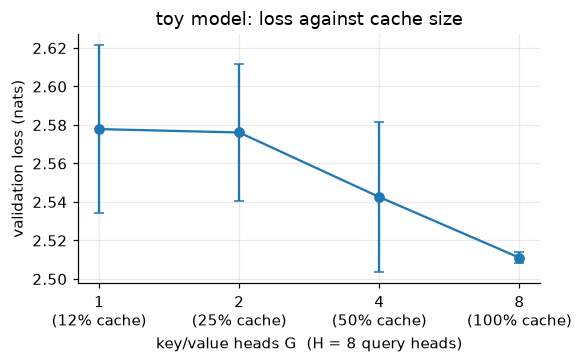

PASS - MQA is not better than MHA beyond noise by more than one spread MQA - MHA = +0.067, spread 0.043


In [10]:
Gs, seeds = [8, 4, 2, 1], [0, 1, 2]
loss = {}
t0 = time.time()
for G in Gs:
    vals = []
    for s in seeds:
        m = make(G, seed=s)
        A.train_lm(m, data, steps=400, B=32, T=64, lr=3e-3, seed=s)
        vals.append(A.evaluate(m, data))
    loss[G] = np.array(vals)
    n = sum(p.numel() for p in m.parameters())
    print(f"G={G}: val loss {loss[G].mean():.3f} +- {loss[G].std():.3f}  (3 seeds)  params {n:,}  cache {G / H:.3f} of MHA")
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.errorbar(Gs, [loss[g].mean() for g in Gs], [loss[g].std() for g in Gs], marker="o", color=C["blue"], capsize=3)
ax.set_xscale("log", base=2); ax.set_xticks(Gs); ax.set_xticklabels([f"{g}\n({g / H:.0%} cache)" for g in Gs])
ax.set_xlabel("key/value heads G  (H = 8 query heads)"); ax.set_ylabel("validation loss (nats)")
ax.set_title("toy model: loss against cache size"); plt.tight_layout(); plt.show()

spread = max(loss[g].std() for g in Gs)
gap = loss[1].mean() - loss[8].mean()
check("MQA is not better than MHA beyond noise by more than one spread", gap > -spread, f"MQA - MHA = {gap:+.3f}, spread {spread:.3f}")

In [11]:
gap4 = loss[4].mean() - loss[8].mean()
print(f"GQA-4 minus MHA: {gap4:+.3f} nats;  GQA-2: {loss[2].mean() - loss[8].mean():+.3f};  MQA: {loss[1].mean() - loss[8].mean():+.3f}   (seed spread {spread:.3f})")

GQA-4 minus MHA: +0.032 nats;  GQA-2: +0.065;  MQA: +0.067   (seed spread 0.043)


Read the plot as a trade: moving right gives a smaller cache. What the toy shows is how large the loss gap is compared with the spread between seeds. At this scale, with 8 heads of width 8 on character data, the differences are small, which is in line with the paper's finding that GQA with a moderate number of groups is close to MHA. **We are not claiming this proves it for large models**: a toy model with $d_h=8$ and a few hundred steps cannot show whether large models lose anything.

## 7. Measuring a decode step on this machine

Last, the claim that matters in practice: a smaller cache makes the decoding step faster. We implement one decode step by hand with a cache of `S` tokens, with the grouped layout kept as is, so that **no copy of the cache is made**. The queries of a group are stacked and multiply the same stored keys, so the cache is read once per group, not once per query head.

In [12]:
def decode_step(q, K, V):
    """q [H,dh]  K,V [G,S,dh]  ->  out [H,dh].  Query heads of a group share one read of K and V."""
    H_, dh_ = q.shape
    G_ = K.shape[0]
    qg = q.view(G_, H_ // G_, dh_)                                   # [G, H/G, dh]
    p = (qg @ K.transpose(1, 2) / math.sqrt(dh_)).softmax(-1)        # [G, H/G, S]
    return (p @ V).reshape(H_, dh_)

# correctness: the same answer as the repeat_interleave version of the layer
Hh, dhh, S = 8, 16, 100
Gg = 2
q, K, V = torch.randn(Hh, dhh), torch.randn(Gg, S, dhh), torch.randn(Gg, S, dhh)
ref = F.scaled_dot_product_attention(q[:, None], K.repeat_interleave(Hh // Gg, 0), V.repeat_interleave(Hh // Gg, 0))[:, 0]
check("grouped decode step equals expanded attention", (decode_step(q, K, V) - ref).abs().max().item() < 1e-5)

def bench(G, H_=32, dh_=128, S=16384, layers=8, reps=5):
    torch.manual_seed(0)
    q = torch.randn(H_, dh_)
    Ks = [torch.randn(G, S, dh_) for _ in range(layers)]               # separate caches so nothing stays in CPU cache
    Vs = [torch.randn(G, S, dh_) for _ in range(layers)]
    for _ in range(2):
        for K_, V_ in zip(Ks, Vs): decode_step(q, K_, V_)
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        for K_, V_ in zip(Ks, Vs): decode_step(q, K_, V_)
        ts.append(time.perf_counter() - t0)
    return min(ts) / layers * 1e3

times = {G: bench(G) for G in [32, 8, 4, 1]}
print(f"{'G':>3s} {'ms per layer-step':>18s} {'speed-up vs MHA':>16s} {'cache MB per layer':>19s}")
for G, t in times.items():
    print(f"{G:3d} {t:18.2f} {times[32] / t:15.1f}x {2 * G * 16384 * 128 * 4 / 1e6:19.0f}")
check("fewer kv heads decode faster here (G=8 faster than G=32)", times[8] < times[32])
check("MQA is the fastest", times[1] == min(times.values()))

PASS - grouped decode step equals expanded attention 


  G  ms per layer-step  speed-up vs MHA  cache MB per layer
 32               9.11             1.0x                 537
  8               4.37             2.1x                 134
  4               2.15             4.2x                  67
  1               0.90            10.2x                  17
PASS - fewer kv heads decode faster here (G=8 faster than G=32) 
PASS - MQA is the fastest 


This is a CPU measured with 32-bit numbers on a laptop shared with other jobs, not a GPU serving real batches, so read it for direction. Expect a speed-up smaller than $H/G$: some time goes to softmax and to the work that does not scale with the cache. On GPUs with half-precision caches the same arithmetic holds, and the paper reports the same pattern at scale (its Figure 3 and 6).

## What this notebook did and did not show

**Shown (checks above).** GQA is exactly MHA with tied key/value heads, so it is a constraint and not new machinery. The cache is $2Gd_h$ per token per layer. Mean-pooling is the best conversion recipe in our toy test, and a little uptraining recovers most of the loss. A decoding step that reads the grouped cache once per group is faster on CPU in proportion, at least approximately, to the cache size.

**Not shown.** Whether quality is unchanged for large models trained for trillions of tokens (the paper uses T5 on summarisation and translation; we use a tiny character model, and differences between settings are within a few seed spreads). Real serving speed on GPUs with batching. How the head count should be chosen: the paper reports $G=8$ as a good middle for large models, but our toy has only 8 heads.

**Next.** Notebook 2 adds a learned **gate** on the attention output, which the same family of models has started to adopt.

In [13]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 13 | failed: 0
